# Video offset check on the 20 example EODs (3-fish recording)

Frames 34056 and 14111 fit the recording much better with the masks of ~6 video frames earlier (−120 ms at 50 fps). Here, for the
20 examples of `examples_mine_vs_denis_better/` (5 each: both right, only mine right, only Denis right, both wrong), my model
(BEM σ, sink at the tail tip, other fish as bodies) is rebuilt from the masks and midlines of frame `Frame + OFFSET`, for the
emitting fish only (fish 0), and compared with the same recorded EOD (L2 distance d, patterns × −1, max |v| = 1). Offset 0
reproduces the cached model.

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eod_examples as ex
%matplotlib inline
from compute_electric_field import (multipole_sources, build_multipole_b, occupancy_field, build_A_shell, solve_potential, gammas,
                                    unflatten_to_grid)
from eod_assign import pair_voltages

OFFSET = -6                                                         # video frames (-120 ms at 50 fps)
EX_DIR = 'results/eod_ground_truth_3fish/conductivities/examples_mine_vs_denis_better'
OUT = 'results/eod_ground_truth_3fish/conductivities/debug_frames'
N = 150; h = 1 / (N - 1); CELL_CM = (912 - 1) / (N - 1) / ex.PX_PER_CM
BEM = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=100.0, eps_interior=0.0,
           sigma_skin=1 / (0.1 / 0.005 + 1 / 100.0), eps_skin=0.0)
DELTA_H = 0.005 / CELL_CM; gw, gs, gi = gammas(0.0, **BEM)
c = ex.emitter_usual_lengths(ex.use_better_list(ex.load_recording('3-fish'))); em = c['emitter']; P = c['P']

def u_for(fms, f, mid):
    '''My model pattern (x -1, max |v| = 1), fish f emitting, all masks fms; None if f has no midline.'''
    if mid is None: return None
    v = -pair_voltages(unflatten_to_grid(solve_potential(build_A_shell(occupancy_field(fms, N, skip=f), N, DELTA_H, gw, gs, gi),
                       build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=0.0), h, N)), N).real, c['pairs'], N)
    return v / np.abs(v).max()
def heading(mid): t = (mid[-1] - mid[0]) * [-1, 1]; return np.degrees(np.arctan2(t[0], t[1]))

## d at offset 0 and at `OFFSET`

In [2]:
PAT = re.compile(r'^(\d+)_(.+?)_([\d.]+)cm_frame(\d+)\.png$')               # (macOS '._' files skipped)
rows = []
for fn in sorted(f for f in os.listdir(EX_DIR) if PAT.match(f)):
    n_, cat, gap, frame = PAT.match(fn).groups(); frame = int(frame)
    i = int(c['df'].index[c['df'].Frame == frame][0]); r, U = ex.my_patterns(c, i)
    row = dict(n=int(n_), outcome=cat.replace('_', ' '), gap_cm=float(gap), frame=frame, eod_row=i)
    heads = {}
    for off in (0, OFFSET):
        fms = ex.frame_masks(c, frame + off); mds = ex.fish_midlines(fms); u = u_for(fms, em, mds[em])
        row[f'd_{off}'] = np.nan if u is None else np.linalg.norm(u - r)
        row[f'heading_{off}'] = heading(mds[em]) if mds[em] is not None else np.nan; heads[off] = mds[em][-1] * (P - 1) if mds[em] is not None else np.full(2, np.nan)
    assert np.isclose(row['d_0'], np.linalg.norm(U[em] - r), atol=1e-6)   # offset 0 = cached model
    row['head_moved_cm'] = np.linalg.norm(heads[0] - heads[OFFSET]) / ex.PX_PER_CM
    row['turn_deg'] = (row['heading_0'] - row[f'heading_{OFFSET}'] + 180) % 360 - 180
    rows.append(row)
T = pd.DataFrame(rows); T['change'] = T[f'd_{OFFSET}'] - T.d_0
pd.set_option('display.width', 250)
print(T[['n', 'outcome', 'frame', 'gap_cm', 'head_moved_cm', 'turn_deg', 'd_0', f'd_{OFFSET}', 'change']].round(2).to_string(index=False))
print(f"\noffset {OFFSET} ({1000 * OFFSET / c['fps']:+.0f} ms) vs the EOD's frame, fish {em} only, 20 examples: d lower in {(T.change < 0).sum()}, higher in {(T.change > 0).sum()}; "
      f"median d {T.d_0.median():.2f} -> {T[f'd_{OFFSET}'].median():.2f}; median change {T.change.median():+.2f}")
for o, g in T.groupby('outcome', sort=False):
    print(f"  {o:17s}: median d {g.d_0.median():.2f} -> {g[f'd_{OFFSET}'].median():.2f}, lower in {(g.change < 0).sum()}/{len(g)}")
moving = T.head_moved_cm > 1.0
print(f"  fish {em} head moved > 1 cm in {OFFSET} frames: {moving.sum()} examples, d lower in {(T.change[moving] < 0).sum()}; "
      f"moved <= 1 cm: {(~moving).sum()}, d lower in {(T.change[~moving] < 0).sum()}")

 n          outcome  frame  gap_cm  head_moved_cm  turn_deg  d_0  d_-6  change
 1       both right  24227     4.1           2.24     -5.97 0.36  0.69    0.32
 2       both right  14111     9.5           0.23      7.75 0.92  0.46   -0.46
 3       both right   9942    13.2           5.43    -49.93 0.45  0.60    0.15
 4       both right  13904    15.6           0.21      9.23 1.27  0.65   -0.62
 5       both right  22296    28.2           1.05     12.39 0.59  0.32   -0.27
 6  only mine right  16883     2.5           0.49     16.21 1.23  0.36   -0.86
 7  only mine right  16679     6.2           3.41      9.52 1.53  1.47   -0.06
 8  only mine right  17474    12.1           4.43    -52.41 1.23  0.26   -0.98
 9  only mine right   7524    14.7           0.32    -12.71 1.42  1.72    0.30
10  only mine right  34056    27.0           3.20     33.95 1.76  0.30   -1.47
11 only Denis right   9922     2.5           1.36     18.32 1.99  0.18   -1.81
12 only Denis right   9873     9.6           4.11   

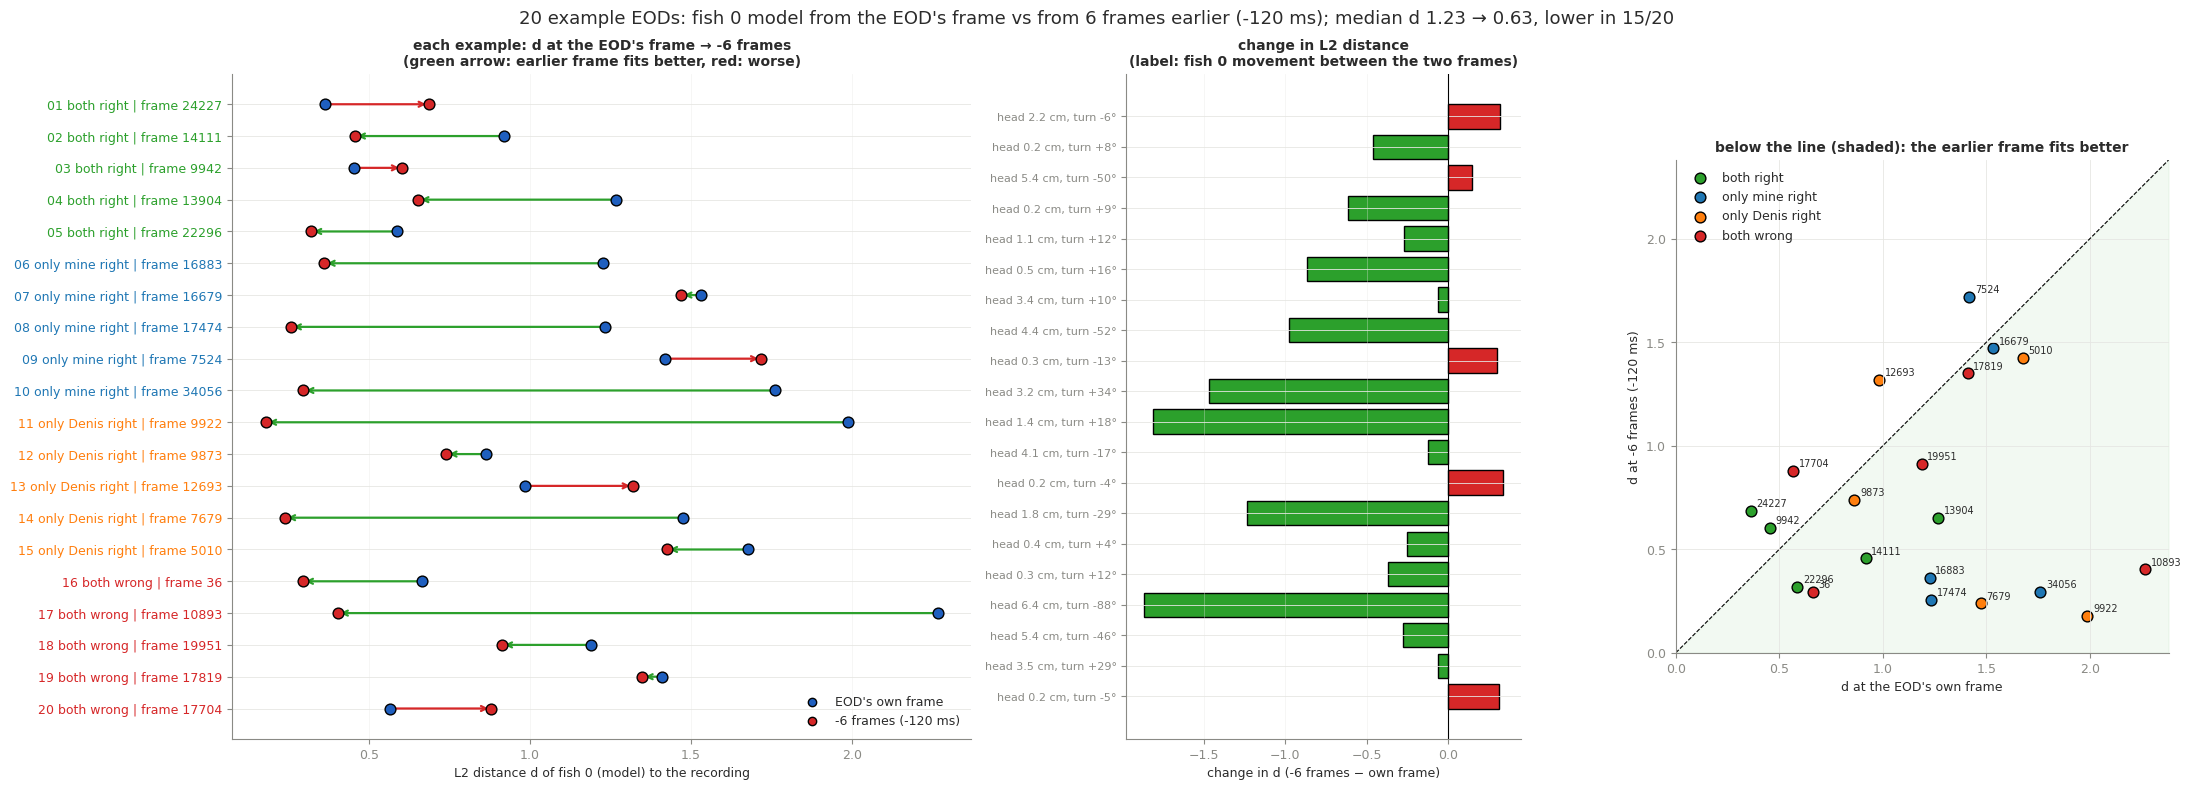

In [3]:
OC = {'both right': 'tab:green', 'only mine right': 'tab:blue', 'only Denis right': 'tab:orange', 'both wrong': 'tab:red'}
dO = f'd_{OFFSET}'; ms_ = f'{1000 * OFFSET / c["fps"]:+.0f} ms'
fig, axs = plt.subplots(1, 3, figsize=(22, 8), gridspec_kw=dict(width_ratios=[1.5, 0.8, 1]))
a = axs[0]; y = np.arange(len(T))[::-1]
for yy, (_, t) in zip(y, T.iterrows()):
    a.annotate('', (t[dO], yy), (t.d_0, yy), arrowprops=dict(arrowstyle='->', color='tab:green' if t.change < 0 else 'tab:red', lw=1.6))
    a.scatter(t.d_0, yy, s=60, color=ex.C_MINE, edgecolor='k', zorder=3); a.scatter(t[dO], yy, s=60, color='tab:red', edgecolor='k', zorder=3)
a.set_yticks(y); a.set_yticklabels([f"{t.n:02d} {t.outcome} | frame {t.frame}" for _, t in T.iterrows()], fontsize=9)
for lab, (_, t) in zip(a.get_yticklabels(), T.iterrows()): lab.set_color(OC[t.outcome])
a.scatter([], [], color=ex.C_MINE, edgecolor='k', label="EOD's own frame"); a.scatter([], [], color='tab:red', edgecolor='k', label=f'{OFFSET} frames ({ms_})')
a.set_xlabel(f'L2 distance d of fish {em} (model) to the recording'); a.grid(axis='x', alpha=0.4); a.legend(fontsize=9, loc='lower right')
a.set_title(f'each example: d at the EOD\'s frame → {OFFSET} frames\n(green arrow: earlier frame fits better, red: worse)')
a = axs[1]
a.barh(y, T.change, color=['tab:green' if x < 0 else 'tab:red' for x in T.change], edgecolor='k')
a.axvline(0, color='k', lw=0.8); a.set_yticks(y); a.set_yticklabels([f"head {t.head_moved_cm:.1f} cm, turn {t.turn_deg:+.0f}°" for _, t in T.iterrows()], fontsize=8)
a.set_xlabel(f'change in d ({OFFSET} frames − own frame)'); a.grid(axis='x', alpha=0.4)
a.set_title(f'change in L2 distance\n(label: fish {em} movement between the two frames)')
a = axs[2]; lim = [0, max(T.d_0.max(), T[dO].max()) * 1.05]
a.plot(lim, lim, 'k--', lw=0.8); a.fill_between(lim, lim, [0, 0], color='tab:green', alpha=0.06)
for o, g in T.groupby('outcome', sort=False): a.scatter(g.d_0, g[dO], s=60, color=OC[o], edgecolor='k', label=o)
for _, t in T.iterrows(): a.annotate(str(t.frame), (t.d_0, t[dO]), xytext=(4, 3), textcoords='offset points', fontsize=7)
a.set(xlim=lim, ylim=lim, aspect='equal', xlabel="d at the EOD's own frame", ylabel=f'd at {OFFSET} frames ({ms_})',
      title=f'below the line (shaded): the earlier frame fits better')
a.legend(fontsize=9, loc='upper left')
fig.suptitle(f'20 example EODs: fish {em} model from the EOD\'s frame vs from {abs(OFFSET)} frames earlier ({ms_}); median d {T.d_0.median():.2f} → {T[dO].median():.2f}, '
             f'lower in {(T.change < 0).sum()}/20', fontsize=13)
plt.tight_layout(); fig.savefig(f'{OUT}/offset{OFFSET:+d}_examples_mine_vs_denis.png', dpi=100, bbox_inches='tight'); plt.show()